In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

import xgboost as xgb
import lightgbm as lgb

import joblib

from sklearn.model_selection import RandomizedSearchCV

In [2]:
df = pd.read_csv(
    "../data/processed_train.csv",
    parse_dates=["Date"]
)

In [3]:
train_df = df[df["Date"] < "2015-06-15"]

valid_df = df[
    (df["Date"] >= "2015-06-15") &
    (df["Date"] < "2015-08-01")
]

test_df = df[df["Date"] >= "2015-08-01"]

In [4]:
target = "Sales"

drop_cols = [
    "Sales",
    "Customers",
    "Date"
]

X_train = train_df.drop(columns=drop_cols)

y_train = train_df[target]

X_valid = valid_df.drop(columns=drop_cols)

y_valid = valid_df[target]

X_test = test_df.drop(columns=drop_cols)

y_test = test_df[target]

In [5]:
def evaluate(model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print("="*50)
    print(model_name)
    print("="*50)
    print(f"MAE : {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R²  : {r2:.4f}")

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [6]:
baseline = LinearRegression()

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_valid)

baseline_result = evaluate(
    "Linear Regression",
    y_valid,
    baseline_pred
)

Linear Regression
MAE : 1986.49
RMSE: 2698.86
R²  : 0.2367


In [8]:
xgb_model = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_valid)

xgb_result = evaluate(
    "XGBoost",
    y_valid,
    xgb_pred
)

XGBoost
MAE : 869.90
RMSE: 1192.31
R²  : 0.8510


In [9]:
lgb_model = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42
)

lgb_model.fit(X_train, y_train)

lgb_pred = lgb_model.predict(X_valid)

lgb_result = evaluate(
    "LightGBM",
    y_valid,
    lgb_pred
)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.024238 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1077
[LightGBM] [Info] Number of data points in the train set: 798486, number of used features: 24
[LightGBM] [Info] Start training from score 6945.133903
LightGBM
MAE : 1163.93
RMSE: 1576.26
R²  : 0.7396


In [11]:
results = pd.DataFrame([
    baseline_result,
    xgb_result,
    lgb_result
])

results.sort_values("RMSE")

,Model,MAE,RMSE,R2
1,XGBoost,869.898132,1192.314870,0.851029
2,LightGBM,1163.926060,1576.264884,0.739638
0,Linear Regression,1986.494362,2698.861517,0.236725


In [19]:
param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [4, 6, 8, 10],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}

xgb_model = xgb.XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    tree_method="hist"
)

tscv = TimeSeriesSplit(n_splits=3)

search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=10,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=42,
    verbose=2,
    n_jobs=-1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_

print(search.best_params_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
{'subsample': 0.8, 'n_estimators': 500, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.8}


In [15]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_valid)

evaluate(
    "XGBoost",
    y_valid,
    xgb_pred
)

XGBoost
MAE : 785.88
RMSE: 1099.94
R²  : 0.8732


{'Model': 'XGBoost',
 'MAE': 785.884765625,
 'RMSE': np.float64(1099.9385778305987),
 'R2': 0.873218297958374}

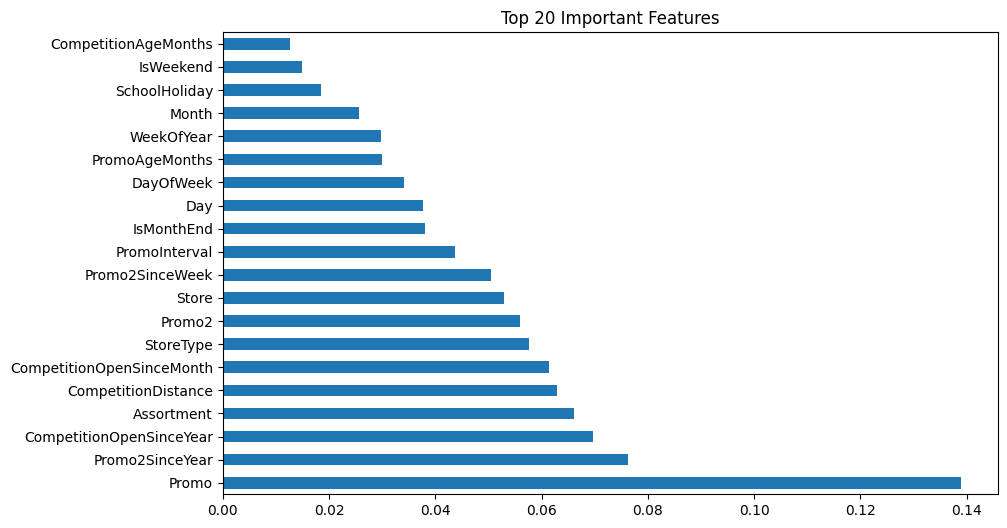

In [16]:
importance = pd.Series(
    xgb_model.feature_importances_,
    index=X_train.columns
)

importance = importance.sort_values(ascending=False)

plt.figure(figsize=(10,6))

importance.head(20).plot(kind="barh")

plt.title("Top 20 Important Features")

plt.show()

In [18]:
joblib.dump(
    xgb_model,
    "../models/xgboost_model.pkl"
)

['../models/xgboost_model.pkl']